# Explore the step 7 poker environment

Inspect the six actions, dictionary observations, nine seat slots, and public action history.
Then test complete hands and visualize 1,000 hands of random legal play.

Select the project's **.venv / Python 3.12** kernel and run the cells from top to bottom.
After editing the Python modules, restart the kernel and run all cells again.
The notebook calls your existing modules; it does not edit them.

The game is still heads-up. Seat slot **0 is the learner**, slot **1 is the opponent**,
and the other seven slots are unused. One big blind (BB) equals two chips.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path("/Users/qxd/Programming/bluffbot")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

assert Path(sys.prefix).resolve() == (PROJECT_ROOT / ".venv").resolve(), (
    "Select the project's .venv kernel."
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from bluffbot.env import HeadsUpEnv
from bluffbot.actions import Action, NUM_ACTIONS, action_options
from bluffbot.observations import (
    CARD_INDEX,
    HISTORY_KINDS,
    MAX_SEATS,
    SEAT_FEATURES,
    TABLE_FEATURES,
)

ACTION_NAMES = ["Fold", "Check/Call", "Minimum raise", "Half-pot", "Pot", "All-in"]
STREET_NAMES = ["Preflop", "Flop", "Turn", "River"]
CARD_NAMES = {index: repr(card) for card, index in CARD_INDEX.items()}

assert len(ACTION_NAMES) == NUM_ACTIONS
print("Python:", sys.executable)
print("Project:", PROJECT_ROOT)

Python: /Users/qxd/Programming/bluffbot/.venv/bin/python
Project: /Users/qxd/Programming/bluffbot


## Small display helpers

Cards use a 52-element array: a **1** marks a visible card and a **0** marks an absent card.
`table` and `seats` use the field names imported above. Monetary fields are in BB.

These helpers turn the arrays into readable tables. They do not reveal the opponent's cards.

In [2]:
def card_names(encoded_cards):
    cards = [CARD_NAMES[index] for index in np.flatnonzero(encoded_cards)]
    return " ".join(cards) if cards else "None"


def action_table(env, info):
    amounts = [
        amount if amount is not None else "—"
        for amount in info["action_raise_to"]
    ]
    return pd.DataFrame({
        "ID": range(NUM_ACTIONS),
        "Action": ACTION_NAMES,
        "Legal": env.action_masks(),
        "Raise-to total (chips)": amounts,
    })


def show_state(env, observation, info):
    table = pd.Series(observation["table"], index=TABLE_FEATURES)
    street = int(round(table["street_fraction"] * 3))

    print("Hand active:", bool(env.state.status))
    print("Street:", STREET_NAMES[street])
    print("Own cards:", card_names(observation["own_cards"]))
    print("Board:", card_names(observation["board_cards"]))
    print("Learner decisions:", info["learner_decisions"])

    display(table.rename("Encoded value").to_frame())

    seats = pd.DataFrame(observation["seats"], columns=SEAT_FEATURES)
    seats.index.name = "Relative seat slot"
    seats.insert(0, "occupied", observation["seat_mask"].astype(int))
    display(seats)
    display(action_table(env, info))

    if "profit_bb" in info:
        print("Final stacks (engine seat order):", info["final_stacks"])
        print(f"Learner profit: {info['profit_bb']:+.1f} BB")

In [3]:
def history_table(observation):
    rows = []
    street_start = 1 + MAX_SEATS
    kind_start = street_start + 4

    for row in observation["history"]:
        if row[0] == 0:
            continue

        actor = int(np.argmax(row[1:street_start]))
        street = int(np.argmax(row[street_start:kind_start]))
        kind = HISTORY_KINDS[int(np.argmax(row[kind_start:kind_start + 5]))]
        added = int(round(row[-2] * HeadsUpEnv.BIG_BLIND))
        raise_to = int(round(row[-1] * HeadsUpEnv.BIG_BLIND))

        rows.append({
            "Actor slot": actor,
            "Street": STREET_NAMES[street],
            "Action": kind,
            "Chips added": added,
            "Raise-to total": raise_to if kind == "raise" else "—",
        })

    return pd.DataFrame(rows)


def check_observation(env, observation):
    assert env.observation_space.contains(observation)
    assert np.array_equal(observation["legal_actions"], env.action_masks())
    assert observation["seat_mask"].sum() == 2
    assert not observation["seats"][2:].any()
    assert sum(env.state.stacks) + env.state.total_pot_amount == 400

## 1. Start a hand and inspect the observation

A seed makes the cards reproducible. Passing a seed also restarts the button rotation;
use `reset()` without a seed for subsequent hands.

The mask marks unused seat slots separately from folded players.
Player-count features are divided by nine, and the street is divided by three.

In [6]:
env = HeadsUpEnv()
observation, info = env.reset(seed=42)
terminated = False

check_observation(env, observation)
assert observation["own_cards"].sum() == 2
assert observation["board_cards"].sum() == 0

show_state(env, observation, info)

display(pd.DataFrame([
    {"Field": name, "Shape": values.shape, "Type": str(values.dtype)}
    for name, values in observation.items()
]))

Hand active: True
Street: Preflop
Own cards: 3s Jh
Board: None
Learner decisions: 0


,Encoded value
street_fraction,0.000000
pot_bb,1.500000
call_bb,0.500000
minimum_raise_to_bb,2.000000
maximum_raise_to_bb,100.000000
player_count_fraction,0.222222
remaining_count_fraction,0.222222
learner_is_button,1.000000


,occupied,stack_bb,street_bet_bb,committed_bb,in_hand,folded,all_in,is_button,is_small_blind,is_big_blind
Relative seat slot,,,,,,,,,,
0,1,99.5,0.5,0.5,1.0,0.0,0.0,1.0,1.0,0.0
1,1,99.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,ID,Action,Legal,Raise-to total (chips)
0,0,Fold,True,—
1,1,Check/Call,True,—
2,2,Minimum raise,True,4
3,3,Half-pot,False,—
4,4,Pot,True,6
5,5,All-in,True,200


,Field,Shape,Type
0,own_cards,"(52,)",float32
1,board_cards,"(52,)",float32
2,table,"(8,)",float32
3,seat_mask,"(9,)",float32
4,seats,"(9, 9)",float32
5,history,"(16, 21)",float32
6,legal_actions,"(6,)",float32


### Visualize the nine reserved seats

Stacks are in BB. The status grid shows the six flag columns from the seat observation.
Unused slots have zero stacks and zero flags.

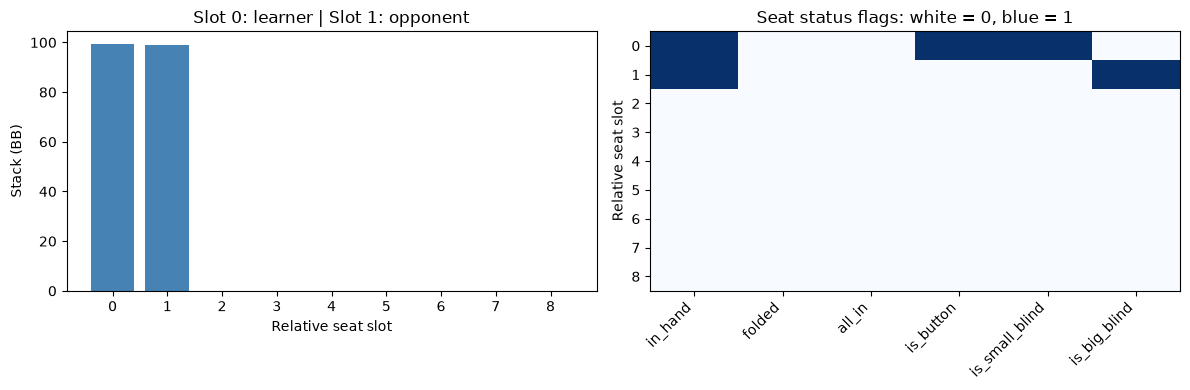

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
slots = np.arange(MAX_SEATS)
colors = ["steelblue" if used else "lightgray" for used in observation["seat_mask"]]

axes[0].bar(slots, observation["seats"][:, 0], color=colors)
axes[0].set(xticks=slots, xlabel="Relative seat slot", ylabel="Stack (BB)")
axes[0].set_title("Slot 0: learner | Slot 1: opponent")

axes[1].imshow(observation["seats"][:, 3:], vmin=0, vmax=1, cmap="Blues", aspect="auto")
axes[1].set_xticks(range(6), SEAT_FEATURES[3:], rotation=45, ha="right")
axes[1].set_yticks(slots)
axes[1].set_ylabel("Relative seat slot")
axes[1].set_title("Seat status flags: white = 0, blue = 1")

plt.tight_layout()
plt.show()
plt.close(fig)

## 2. Verify sizing and duplicate masks

At the initial small-blind decision, the pot is 3 chips and calling costs 1 chip.
A half-pot raise-to is **1 + 1 + (3 + 1) / 2 = 4 chips**.
The minimum raise is also 4, so half-pot is masked as a duplicate.
A pot raise-to is **1 + 1 + (3 + 1) = 6 chips**.

Raise-to totals include chips already bet on this street. An all-in call uses
**Check/Call**. Duplicate raises keep the lowest action ID.

In [8]:
sizing_env = HeadsUpEnv()
_, sizing_info = sizing_env.reset(seed=42)

assert sizing_info["action_raise_to"] == (None, None, 4, None, 6, 200)
assert sizing_env.action_masks().tolist() == [True, True, True, False, True, True]
display(action_table(sizing_env, sizing_info))

try:
    sizing_env.step(Action.HALF_POT)
except ValueError as error:
    print("Expected rejection:", error)
else:
    raise AssertionError("A duplicate action was accepted.")

sizing_obs, reward, done, truncated, sizing_info = sizing_env.step(Action.POT)
assert not done and not truncated and reward == 0
assert sizing_env.state.total_pot_amount == 12
assert sizing_info["action_raise_to"] == (None, None, 2, 6, 12, 194)
check_observation(sizing_env, sizing_obs)

print("After raising to 6 and the opponent calling, the flop pot is 12 chips.")
display(action_table(sizing_env, sizing_info))
sizing_env.close()

,ID,Action,Legal,Raise-to total (chips)
0,0,Fold,True,—
1,1,Check/Call,True,—
2,2,Minimum raise,True,4
3,3,Half-pot,False,—
4,4,Pot,True,6
5,5,All-in,True,200


Expected rejection: Illegal or duplicate action: 3
After raising to 6 and the opponent calling, the flop pot is 12 chips.


,ID,Action,Legal,Raise-to total (chips)
0,0,Fold,False,—
1,1,Check/Call,True,—
2,2,Minimum raise,True,2
3,3,Half-pot,True,6
4,4,Pot,True,12
5,5,All-in,True,194


## 3. Take one learner action

Change `action` below to any `Action` member. Rerun the cell to take another action.
If the hand is finished, rerun section 1's start-hand cell first.
The wrapper handles the opponent and dealing between learner decisions.

The history shows only public actions, from oldest to newest, up to the latest 16.
An actor slot of 0 is the learner; 1 is the opponent. A check adds zero chips.

In [12]:
action = Action.POT  # Try CHECK_CALL, MIN_RAISE, HALF_POT, or ALL_IN.

if terminated:
    print("Hand finished. Rerun the start-hand cell in section 1.")
elif not env.action_masks()[action]:
    print("This action is illegal or duplicates another choice.")
    display(action_table(env, info))
else:
    observation, reward, terminated, truncated, info = env.step(action)
    check_observation(env, observation)
    assert not truncated

    print("Selected:", ACTION_NAMES[action])
    print("Reward:", reward, "BB")
    show_state(env, observation, info)
    display(history_table(observation))

Selected: Pot
Reward: 81.0 BB
Hand active: False
Street: River
Own cards: 3s Jh
Board: 3d 6d 7s 9d Ad
Learner decisions: 4


,Encoded value
street_fraction,1.000000
pot_bb,0.000000
call_bb,0.000000
minimum_raise_to_bb,0.000000
maximum_raise_to_bb,0.000000
player_count_fraction,0.222222
remaining_count_fraction,0.222222
learner_is_button,1.000000


,occupied,stack_bb,street_bet_bb,committed_bb,in_hand,folded,all_in,is_button,is_small_blind,is_big_blind
Relative seat slot,,,,,,,,,,
0,1,181.0,0.0,81.0,1.0,0.0,0.0,1.0,1.0,0.0
1,1,19.0,0.0,81.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,ID,Action,Legal,Raise-to total (chips)
0,0,Fold,False,—
1,1,Check/Call,False,—
2,2,Minimum raise,False,—
3,3,Half-pot,False,—
4,4,Pot,False,—
5,5,All-in,False,—


Final stacks (engine seat order): (38, 362)
Learner profit: +81.0 BB


,Actor slot,Street,Action,Chips added,Raise-to total
0,1,Preflop,blind,2,—
1,0,Preflop,blind,1,—
2,0,Preflop,raise,5,6
3,1,Preflop,call,4,—
4,1,Flop,check,0,—
5,0,Flop,raise,12,12
6,1,Flop,call,12,—
7,1,Turn,check,0,—
8,0,Turn,raise,36,36
9,1,Turn,call,36,—


## 4. Complete a fresh hand and inspect sparse rewards

This demonstration uses a separate environment. Both players check or call.
The learner receives zero reward before settlement; the final reward is net profit in BB.
The pot drops to zero when chips are paid out.

In [13]:
hand_env = HeadsUpEnv()
hand_obs, hand_info = hand_env.reset(seed=42)
hand_done = False
hand_rows = []

while not hand_done:
    assert len(hand_rows) < 100, "Hand took too many learner decisions."
    hand_obs, hand_reward, hand_done, was_truncated, hand_info = hand_env.step(Action.CHECK_CALL)
    check_observation(hand_env, hand_obs)
    assert not was_truncated

    if not hand_done:
        assert hand_reward == 0.0

    hand_rows.append({
        "Decision": hand_info["learner_decisions"],
        "Pot (BB)": float(hand_obs["table"][1]),
        "Learner stack (BB)": float(hand_obs["seats"][0, 0]),
        "Reward (BB)": hand_reward,
        "Finished": hand_done,
    })

assert sum(hand_info["final_stacks"]) == 400
assert hand_reward == (hand_info["final_stacks"][hand_env.learner_index] - 200) / 2
assert hand_reward == hand_info["profit_bb"]
assert not hand_env.action_masks().any()

hand_results = pd.DataFrame(hand_rows)
display(hand_results)
display(history_table(hand_obs))
show_state(hand_env, hand_obs, hand_info)
hand_env.close()

,Decision,Pot (BB),Learner stack (BB),Reward (BB),Finished
0,1,2.0,99.0,0.0,False
1,2,2.0,99.0,0.0,False
2,3,2.0,99.0,0.0,False
3,4,0.0,101.0,1.0,True


,Actor slot,Street,Action,Chips added,Raise-to total
0,1,Preflop,blind,2,—
1,0,Preflop,blind,1,—
2,0,Preflop,call,1,—
3,1,Preflop,check,0,—
4,1,Flop,check,0,—
5,0,Flop,check,0,—
6,1,Turn,check,0,—
7,0,Turn,check,0,—
8,1,River,check,0,—
9,0,River,check,0,—


Hand active: False
Street: River
Own cards: 3s Jh
Board: 3d 6d 7s 9d Ad
Learner decisions: 4


,Encoded value
street_fraction,1.000000
pot_bb,0.000000
call_bb,0.000000
minimum_raise_to_bb,0.000000
maximum_raise_to_bb,0.000000
player_count_fraction,0.222222
remaining_count_fraction,0.222222
learner_is_button,1.000000


,occupied,stack_bb,street_bet_bb,committed_bb,in_hand,folded,all_in,is_button,is_small_blind,is_big_blind
Relative seat slot,,,,,,,,,,
0,1,101.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
1,1,99.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,ID,Action,Legal,Raise-to total (chips)
0,0,Fold,False,—
1,1,Check/Call,False,—
2,2,Minimum raise,False,—
3,3,Half-pot,False,—
4,4,Pot,False,—
5,5,All-in,False,—


Final stacks (engine seat order): (198, 202)
Learner profit: +1.0 BB


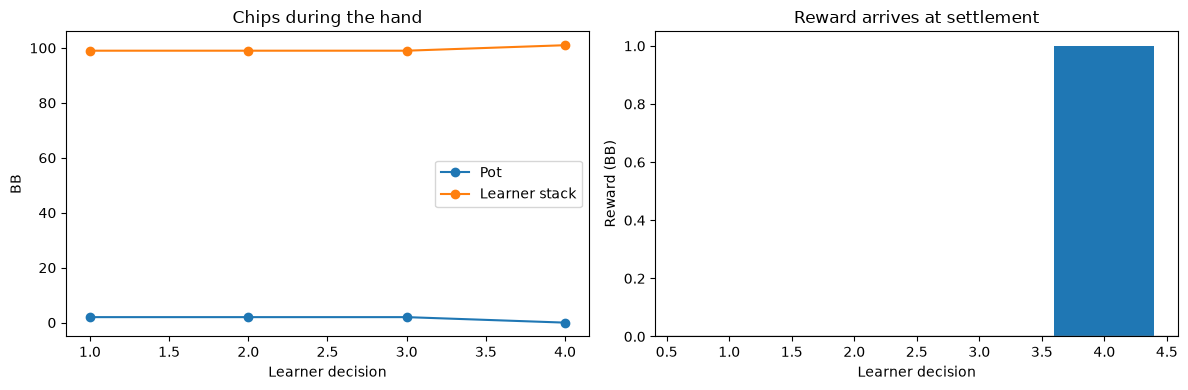

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hand_results["Decision"], hand_results["Pot (BB)"], marker="o", label="Pot")
axes[0].plot(hand_results["Decision"], hand_results["Learner stack (BB)"], marker="o", label="Learner stack")
axes[0].set(xlabel="Learner decision", ylabel="BB", title="Chips during the hand")
axes[0].legend()

axes[1].bar(hand_results["Decision"], hand_results["Reward (BB)"])
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set(xlabel="Learner decision", ylabel="Reward (BB)", title="Reward arrives at settlement")

plt.tight_layout()
plt.show()
plt.close(fig)

## 5. Check folding, all-ins, and position rotation

Folding the small blind should cost 0.5 BB. A preflop all-in against this opponent
should run out all five board cards and settle in one learner decision.
The learner should alternate between button/small blind and big blind.

In [15]:
fold_env = HeadsUpEnv()
fold_env.reset(seed=42)
fold_obs, fold_reward, fold_done, truncated, fold_info = fold_env.step(Action.FOLD)

assert fold_done and not truncated
assert fold_reward == -0.5
assert fold_info["final_stacks"] == (201, 199)
check_observation(fold_env, fold_obs)
print("Small-blind fold: passed (-0.5 BB).")
fold_env.close()

all_in_env = HeadsUpEnv()
all_in_env.reset(seed=42)
all_in_obs, all_in_reward, all_in_done, truncated, all_in_info = all_in_env.step(Action.ALL_IN)

assert all_in_done and not truncated
assert all_in_obs["board_cards"].sum() == 5
assert all_in_info["learner_decisions"] == 1
assert all_in_reward in (-100.0, 0.0, 100.0)
check_observation(all_in_env, all_in_obs)
print("Preflop all-in: passed.", all_in_info)
all_in_env.close()

position_env = HeadsUpEnv()
positions = []
for hand in range(4):
    _, position_info = position_env.reset(seed=42 if hand == 0 else None)
    positions.append(position_info["learner_index"])
    position_env.step(Action.ALL_IN)

assert positions == [1, 0, 1, 0]
print("Position rotation: passed.", positions)
position_env.close()

Small-blind fold: passed (-0.5 BB).
Preflop all-in: passed. {'learner_index': 1, 'learner_is_button': True, 'learner_decisions': 1, 'action_raise_to': (None, None, None, None, None, None), 'final_stacks': (0, 400), 'profit_bb': 100.0}
Position rotation: passed. [1, 0, 1, 0]


## 6. Check hidden-card protection

This diagnostic changes the opponent's private cards and undealt deck in a fresh simulator.
The learner's observation must remain identical. We never display those hidden cards.
This is a focused check, not a complete proof of information isolation.

In [16]:
privacy_env = HeadsUpEnv()
before, _ = privacy_env.reset(seed=42)
opponent = 1 - privacy_env.learner_index

# Swap the opponent's cards with two undealt cards, keeping the deck unique.
old_cards = list(privacy_env.state.hole_cards[opponent])
new_cards = [privacy_env.state.deck_cards.popleft() for _ in range(2)]
privacy_env.state.hole_cards[opponent][:] = new_cards
privacy_env.state.deck_cards.extend(old_cards)
privacy_env.state.deck_cards.reverse()

after = privacy_env._observation()
for field in before:
    np.testing.assert_array_equal(before[field], after[field])

print("Hidden-card and future-deck perturbation: passed.")
privacy_env.close()

Hidden-card and future-deck perturbation: passed.


## 7. Run 1,000 random legal hands

This checks that hands complete, observations fit their declared space, rewards are
consistent, and all 400 chips remain accounted for. It counts learner decisions and
completed hands separately. Seed only the first reset so positions alternate.

The policy is random and the opponent always checks or calls. Profit here is a
simulation diagnostic; it does not demonstrate a trained poker strategy.

In [17]:
N_HANDS = 1_000
simulation = HeadsUpEnv()
action_rng = np.random.default_rng(123)
action_counts = np.zeros(NUM_ACTIONS, dtype=int)
records = []

for hand in range(N_HANDS):
    obs, info = simulation.reset(seed=123 if hand == 0 else None)
    done = False
    decisions = 0
    check_observation(simulation, obs)

    while not done:
        assert decisions < 100, f"Hand {hand + 1} took too many decisions."
        legal_actions = np.flatnonzero(simulation.action_masks())
        assert len(legal_actions) > 0
        action = int(action_rng.choice(legal_actions))
        action_counts[action] += 1

        obs, reward, done, truncated, info = simulation.step(action)
        decisions += 1
        check_observation(simulation, obs)
        assert not truncated

        if not done:
            assert reward == 0.0

    assert sum(info["final_stacks"]) == 400
    assert reward == (info["final_stacks"][simulation.learner_index] - 200) / 2
    assert reward == info["profit_bb"]
    assert decisions == info["learner_decisions"]
    assert not simulation.action_masks().any()

    records.append({
        "hand": hand + 1,
        "profit_bb": reward,
        "learner_decisions": decisions,
        "position": "Button/SB" if info["learner_is_button"] else "Big blind",
    })

results = pd.DataFrame(records)
results["cumulative_profit_bb"] = results["profit_bb"].cumsum()
assert action_counts.sum() == results["learner_decisions"].sum()

print(f"Completed {len(results):,} hands and {action_counts.sum():,} learner decisions.")
print("All simulation checks passed; every selected action was accepted by the engine.")
display(results.head(10))
simulation.close()

Completed 1,000 hands and 2,651 learner decisions.
All simulation checks passed; every selected action was accepted by the engine.


,hand,profit_bb,learner_decisions,position,cumulative_profit_bb
0,1,-0.5,1,Button/SB,-0.5
1,2,-100.0,4,Big blind,-100.5
2,3,-3.0,4,Button/SB,-103.5
3,4,-100.0,3,Big blind,-203.5
4,5,-100.0,2,Button/SB,-303.5
5,6,-100.0,4,Big blind,-403.5
6,7,-100.0,1,Button/SB,-503.5
7,8,-100.0,1,Big blind,-603.5
8,9,-0.5,1,Button/SB,-604.0
9,10,-6.0,4,Big blind,-610.0


In [13]:
summary = pd.Series({
    "Completed hands": len(results),
    "Learner decisions": results["learner_decisions"].sum(),
    "Mean decisions per hand": results["learner_decisions"].mean(),
    "Total profit (BB)": results["profit_bb"].sum(),
    "BB/100": 100 * results["profit_bb"].mean(),
})
display(summary.rename("Value").to_frame().round(3))

display(results.groupby("position").agg(
    hands=("hand", "count"),
    mean_profit_bb=("profit_bb", "mean"),
    mean_decisions=("learner_decisions", "mean"),
).round(3))

display(pd.DataFrame({
    "Action": ACTION_NAMES,
    "Count": action_counts,
    "Share of learner decisions": action_counts / action_counts.sum(),
}))

,Value
Completed hands,1000.000
Learner decisions,2651.000
Mean decisions per hand,2.651
Total profit (BB),-2110.000
BB/100,-211.000


,hands,mean_profit_bb,mean_decisions
position,,,
Big blind,500,-7.856,2.838
Button/SB,500,3.636,2.464


,Action,Count,Share of learner decisions
0,Fold,96,0.036213
1,Check/Call,564,0.212750
2,Minimum raise,565,0.213127
3,Half-pot,289,0.109015
4,Pot,578,0.218031
5,All-in,559,0.210864


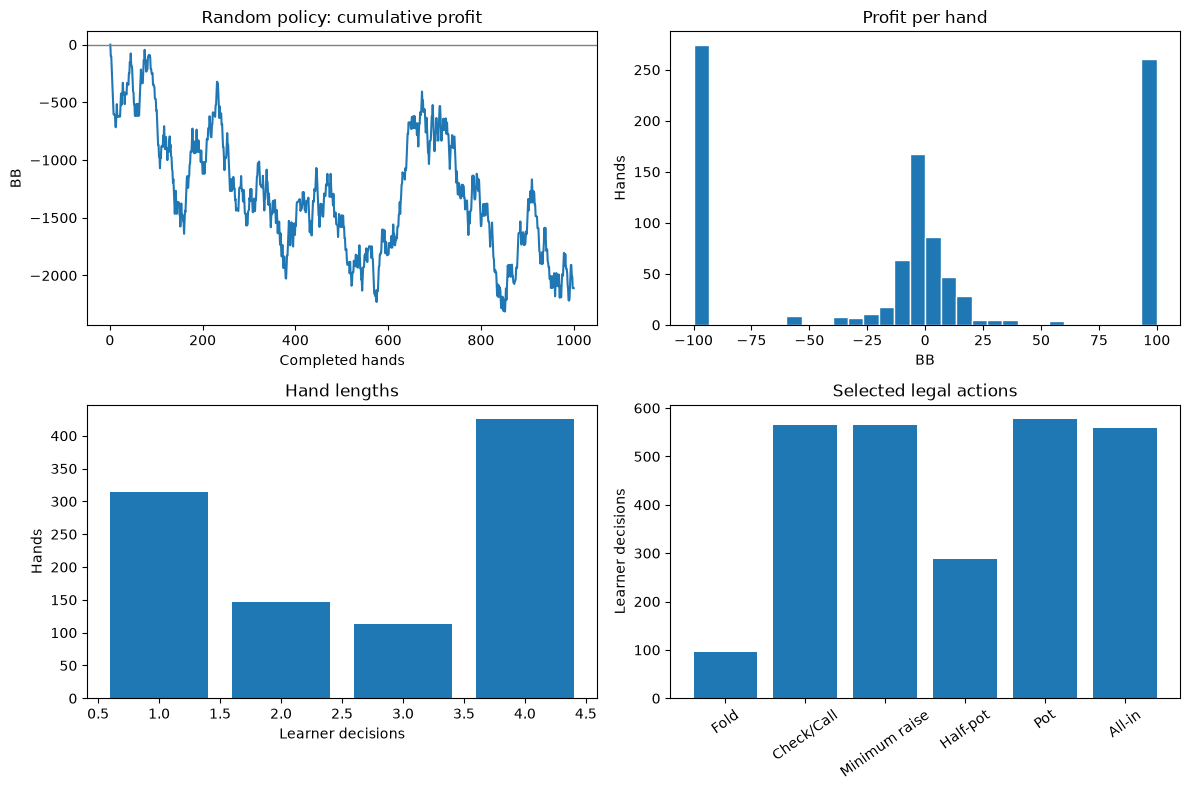

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(results["hand"], results["cumulative_profit_bb"])
axes[0, 0].axhline(0, color="gray", linewidth=1)
axes[0, 0].set(title="Random policy: cumulative profit", xlabel="Completed hands", ylabel="BB")

axes[0, 1].hist(results["profit_bb"], bins=30, edgecolor="white")
axes[0, 1].set(title="Profit per hand", xlabel="BB", ylabel="Hands")

decision_counts = results["learner_decisions"].value_counts().sort_index()
axes[1, 0].bar(decision_counts.index, decision_counts.values)
axes[1, 0].set(title="Hand lengths", xlabel="Learner decisions", ylabel="Hands")

axes[1, 1].bar(ACTION_NAMES, action_counts)
axes[1, 1].tick_params(axis="x", labelrotation=35)
axes[1, 1].set(title="Selected legal actions", ylabel="Learner decisions")

plt.tight_layout()
plt.show()
plt.close(fig)

In [18]:
env.close()
print("Notebook checks complete.")

Notebook checks complete.
